# Vectoranalyse — Squad vol en Squad plus chicks

Deze notebook bevat trigram- en vectoranalyses voor Squad vol en Squad plus chicks. Auteur-aliases uit de WhatsApp-export worden waar nodig samengevoegd.

In [175]:
import sys
from pathlib import Path

repository_root = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "pyproject.toml").is_file()
        and (candidate / "src").is_dir()
    ),
    None,
)
if repository_root is None:
    raise FileNotFoundError("Kan de repository-root niet vinden vanaf de notebookmap.")
sys.path.insert(0, str(repository_root))


In [176]:
from io import TextIOWrapper
from pathlib import Path
import re
from zipfile import ZipFile

import pandas as pd
from IPython.display import display

from wa_analyzer.data import ROOT

ZIP_PATH = ROOT / "data" / "raw" / "Squad vol.zip"
CHAT_DATETIME_FORMAT = "%d-%m-%Y %H:%M"
MESSAGE_HEADER = re.compile(
    r"^(\d{2}-\d{2}-\d{4} \d{2}:\d{2}) - (.*?): (.*)$"
)
TIMESTAMPED_LINE = re.compile(
    r"^(\d{2}-\d{2}-\d{4} \d{2}:\d{2}) - (.*)$"
)

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Chatarchief niet gevonden: {ZIP_PATH}")

with ZipFile(ZIP_PATH) as archive:
    text_members = [
        name for name in archive.namelist() if name.lower().endswith(".txt")
    ]
    if len(text_members) != 1:
        raise ValueError(
            f"Verwacht precies één .txt-chatbestand in {ZIP_PATH.name}; "
            f"gevonden: {len(text_members)}."
        )

    message_records = []
    event_records = []
    last_record_kind = None
    continuation_lines = 0

    with TextIOWrapper(
        archive.open(text_members[0]), encoding="utf-8-sig"
    ) as chat_file:
        for line_number, line in enumerate(chat_file, start=1):
            line = line.rstrip("\r\n")
            message_match = MESSAGE_HEADER.match(line)
            if message_match:
                timestamp_text, author, message = message_match.groups()
                timestamp = pd.to_datetime(
                    timestamp_text,
                    format=CHAT_DATETIME_FORMAT,
                    utc=True,
                    errors="raise",
                )
                message_records.append(
                    (timestamp, author.strip(), message.strip())
                )
                last_record_kind = "message"
                continue

            timestamp_match = TIMESTAMPED_LINE.match(line)
            if timestamp_match:
                timestamp_text, event_text = timestamp_match.groups()
                timestamp = pd.to_datetime(
                    timestamp_text,
                    format=CHAT_DATETIME_FORMAT,
                    utc=True,
                    errors="raise",
                )
                event_records.append((timestamp, event_text.strip()))
                last_record_kind = "event"
                continue

            if last_record_kind == "message":
                timestamp, author, message = message_records[-1]
                message_records[-1] = (
                    timestamp,
                    author,
                    f"{message}\n{line}".strip(),
                )
                continuation_lines += 1
            elif last_record_kind == "event":
                timestamp, event_text = event_records[-1]
                event_records[-1] = (
                    timestamp,
                    f"{event_text}\n{line}".strip(),
                )
                continuation_lines += 1
            elif line.strip():
                raise ValueError(
                    f"Onverwachte regel zonder tijdstempel of voorafgaand record "
                    f"op regel {line_number}."
                )

messages = pd.DataFrame(
    message_records, columns=["timestamp", "author", "message"]
)
chat_events = pd.DataFrame(
    event_records, columns=["timestamp", "event"]
)
messages["message_length"] = messages["message"].str.len()
messages["word_count"] = messages["message"].str.split().str.len()



# Normalize the two aliases used in the original WhatsApp export.
messages["author"] = messages["author"].replace(
    {"Eikel": "Joel", "Vincent": "Vincent Kruithof"}
)
# Exclude sender labels that are only a phone number (no author name).
unnamed_author = messages["author"].str.fullmatch(r"\+?[\d\s().-]+")
messages = messages.loc[~unnamed_author].copy()
print(f"Berichten: {len(messages):,}; auteurs: {messages.author.nunique():,}")
print(f"Periode: {messages.timestamp.min()} t/m {messages.timestamp.max()}")


Berichten: 65,057; auteurs: 13
Periode: 2015-01-06 19:38:00+00:00 t/m 2026-09-18 08:03:00+00:00


## Vectoranalyse van Squad vol

Deze analyse volgt de aanpak uit notebook 06.4, maar gebruikt `messages`: eerst
sessies per auteur, daarna controles op sessieherkenning, schrijfstijl en emoji-sentiment.
De modellen worden hieronder eenmalig klaargezet.

In [177]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from transformers import pipeline as hf_pipeline

from scripts.sessionize import merge_messages, sessionize

EMBEDDER = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
sentiment_model = hf_pipeline(
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    top_k=None,
    truncation=True,
    max_length=512,
)

N_EVAL = 400
PER_AUTHOR = 600
SENTIMENT_SAMPLE = 600

def embed(texts) -> np.ndarray:
    return np.asarray(EMBEDDER.encode(list(texts), batch_size=64, show_progress_bar=False))

def self_retrieval_accuracy(
    frame: pd.DataFrame,
    group_cols: list[str],
    min_messages: int = 6,
    n_eval: int = 400,
    seed: int = 42,
) -> tuple[float, int]:
    sizes = frame.groupby(group_cols).size()
    keys = sizes[sizes >= min_messages].index.tolist()
    rng = np.random.default_rng(seed)
    if len(keys) > n_eval:
        keys = [keys[i] for i in rng.choice(len(keys), size=n_eval, replace=False)]
    if not keys:
        return 0.0, 0

    first, second = [], []
    grouped = frame.sort_values("timestamp").groupby(group_cols)
    for key in keys:
        group = grouped.get_group(key)
        half = len(group) // 2
        first.append(" ".join(group.message.iloc[:half]))
        second.append(" ".join(group.message.iloc[half:]))

    first_vectors, second_vectors = embed(first), embed(second)
    first_vectors /= np.linalg.norm(first_vectors, axis=1, keepdims=True)
    second_vectors /= np.linalg.norm(second_vectors, axis=1, keepdims=True)
    nearest = (first_vectors @ second_vectors.T).argmax(axis=1)
    accuracy = float((nearest == np.arange(len(keys))).mean())
    return accuracy, len(keys)

def race(
    units: pd.DataFrame, per_author: int = 600, seed: int = 42
) -> tuple[dict[str, float], LogisticRegression, CountVectorizer]:
    shuffled = units.sample(frac=1, random_state=seed)
    balanced = shuffled.groupby("author").head(per_author)
    train, test = train_test_split(
        balanced, test_size=0.3, stratify=balanced.author, random_state=seed
    )
    trigrams = CountVectorizer(analyzer="char", ngram_range=(3, 3), min_df=2)
    style_model = LogisticRegression(max_iter=1000).fit(
        trigrams.fit_transform(train.message), train.author
    )
    meaning_model = LogisticRegression(max_iter=1000).fit(
        embed(train.message), train.author
    )
    scores = {
        "raad de meest voorkomende auteur": float(
            test.author.value_counts(normalize=True).max()
        ),
        "trigramfrequenties": float(
            style_model.score(trigrams.transform(test.message), test.author)
        ),
        "sentence embedding": float(
            meaning_model.score(embed(test.message), test.author)
        ),
    }
    return scores, style_model, trigrams

def strongest_trigrams(
    model: LogisticRegression, vectorizer: CountVectorizer, n: int = 8
) -> dict[str, list[str]]:
    vocabulary = vectorizer.get_feature_names_out()
    weights = (
        model.coef_
        if len(model.classes_) > 2
        else np.vstack([-model.coef_[0], model.coef_[0]])
    )
    return {
        author: [vocabulary[j] for j in np.argsort(row)[::-1][:n]]
        for author, row in zip(model.classes_, weights)
    }

def sentiment_check(
    texts: pd.Series, n: int, smile: str, frown: str, seed: int = 0
) -> pd.DataFrame:
    has_smile = texts.str.contains(smile)
    has_frown = texts.str.contains(frown)
    words = texts.str.replace(f"{smile}|{frown}", " ", regex=True)
    words = words.str.replace(r"\s+", " ", regex=True).str.strip()
    typed = pd.Series(
        np.select(
            [has_smile & ~has_frown, has_frown & ~has_smile, ~has_smile & ~has_frown],
            ["typed :)", "typed :(", "no smiley"],
            "both",
        ),
        index=texts.index,
    )
    usable = (typed != "both") & (words.str.count(r"\S+") >= 4)
    picked = (
        pd.DataFrame({"typed": typed[usable], "words": words[usable]})
        .sample(frac=1, random_state=seed)
        .groupby("typed")
        .head(n)
    )
    if picked.empty:
        picked["model says"] = pd.Series(dtype=str)
        return picked
    results = sentiment_model(picked.words.tolist(), batch_size=32)
    scores = pd.DataFrame(
        [{item["label"]: item["score"] for item in result} for result in results],
        index=picked.index,
    )
    picked["model says"] = scores[["positive", "neutral", "negative"]].idxmax(axis=1)
    return picked

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

### Een punt per bericht

Net als in notebook 06.4 projecteren we embeddings van maximaal 1.500 losse berichten naar twee dimensies. We nemen eerst een bericht per auteur, zodat alle auteurs in de grafiek voorkomen; de projectie is een schaduw van de embeddings, geen bewijs dat auteurs goed te onderscheiden zijn.

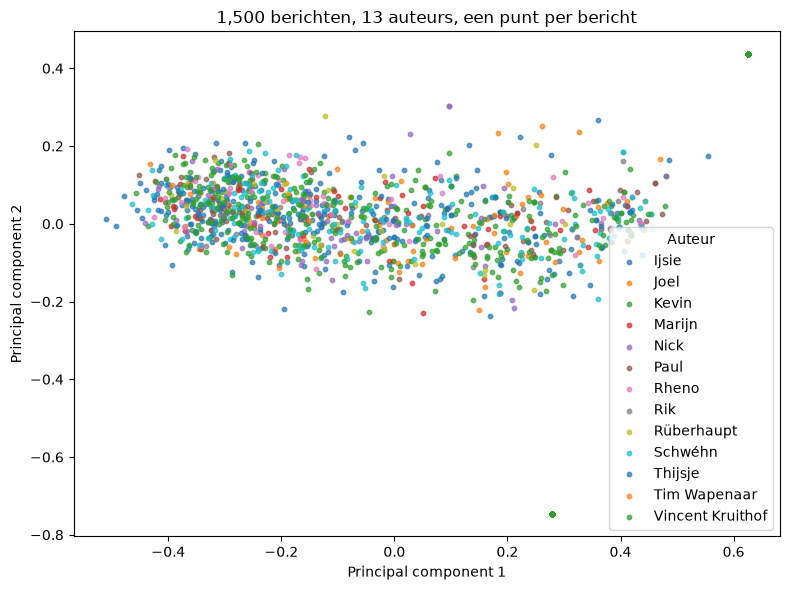

Silhouette by author, in all 384 dimensions: -0.057


In [178]:
if messages.author.nunique() > 1500:
    raise ValueError("Meer dan 1.500 auteurs; niet alle auteurs passen binnen de berichtlimiet.")

author_representatives = messages.groupby("author", group_keys=False).sample(
    n=1, random_state=42
)
remaining_messages = messages.drop(index=author_representatives.index)
additional_count = min(1500 - len(author_representatives), len(remaining_messages))
message_sample = pd.concat(
    [
        author_representatives,
        remaining_messages.sample(n=additional_count, random_state=42),
    ]
)

message_embeddings = embed(message_sample.message)
message_coordinates = PCA(n_components=2).fit_transform(message_embeddings)

fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.get_cmap("tab10")
authors = message_sample.author.unique()
for i, author in enumerate(authors):
    mask = message_sample.author.eq(author).to_numpy()
    ax.scatter(
        message_coordinates[mask, 0],
        message_coordinates[mask, 1],
        label=author,
        color=colors(i % colors.N),
        s=10,
        alpha=0.7,
    )

ax.set_title(f"{len(message_sample):,} berichten, {len(authors)} auteurs, een punt per bericht")
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.legend(title="Auteur")
fig.tight_layout()
plt.show()

print(
    f"Silhouette by author, in all {message_embeddings.shape[1]} dimensions: "
    f"{silhouette_score(message_embeddings, message_sample.author):.3f}"
)

### Berichten samenvoegen tot analyse-eenheden

We vergelijken voor de volledige chat drie manieren om losse berichten samen te voegen: blokken van 15 berichten per auteur, dagen per auteur en sessies per auteur met de vaste drempel van 60 minuten.

In [179]:
unit_messages = messages.sort_values(["author", "timestamp"]).reset_index(drop=True).copy()
unit_messages["session_id"] = sessionize(
    unit_messages, "timestamp", "author", 60 * 60
)

K = 15
unit_messages["window_id"] = unit_messages.groupby("author").cumcount() // K
unit_messages["day"] = unit_messages["timestamp"].dt.date

fixed_units = merge_messages(unit_messages, ["author", "window_id"])
daily_units = merge_messages(unit_messages, ["author", "day"])
session_units = merge_messages(unit_messages, ["author", "session_id"])

for name, units in [
    ("fixed-window", fixed_units),
    ("per-day", daily_units),
    ("session", session_units),
]:
    words = units.message.str.count(r"\S+")
    print(f"{name:>12s}: {len(units):>6,} units, median {words.median():>4.0f} words each")

fixed-window:  4,344 units, median   61 words each
     per-day: 14,035 units, median   10 words each
     session: 21,896 units, median    6 words each


### Sessies per auteur

Een sessie eindigt na een tijdsgat van 60 minuten.

In [180]:
chat = messages.sort_values(["author", "timestamp"]).reset_index(drop=True)
chat_threshold = 60 * 60
chat["session_id"] = sessionize(
    chat, "timestamp", "author", chat_threshold
)
chat_units = merge_messages(chat, ["author", "session_id"])
chat_checkable = chat_units[
    chat_units.n_messages >= 5
].reset_index(drop=True)

print(f"Sessiedrempel: {chat_threshold / 60:.1f} minuten")
print(
    f"{len(chat_units):,} sessies, "
    f"{len(chat_checkable):,} met vijf of meer berichten:"
)
print(chat_checkable.author.value_counts().to_string())

Sessiedrempel: 60.0 minuten
21,896 sessies, 3,671 met vijf of meer berichten:
author
Ijsie               615
Kevin               595
Schwéhn             531
Vincent Kruithof    486
Nick                259
Thijsje             257
Joel                250
Paul                242
Rheno               190
Marijn              143
Rüberhaupt           73
Rik                  27
Tim Wapenaar          3


### Sessies op basis van character-trigrams

Elke rij is één sessie met minimaal tien berichten. TF-IDF geeft meer gewicht aan trigrams die onderscheid maken tussen sessies en minder aan trigrams die overal voorkomen. Omdat de sessiematrix sparse is, gebruiken we TruncatedSVD voor een tweedimensionale projectie. De kleur toont de auteur; het puntsymbool toont de zelf ingedeelde straattaalgroep. Nabijheid in deze projectie is alleen verkennend: het is geen toets of auteurs of onderwerpen echt in groepen vallen.

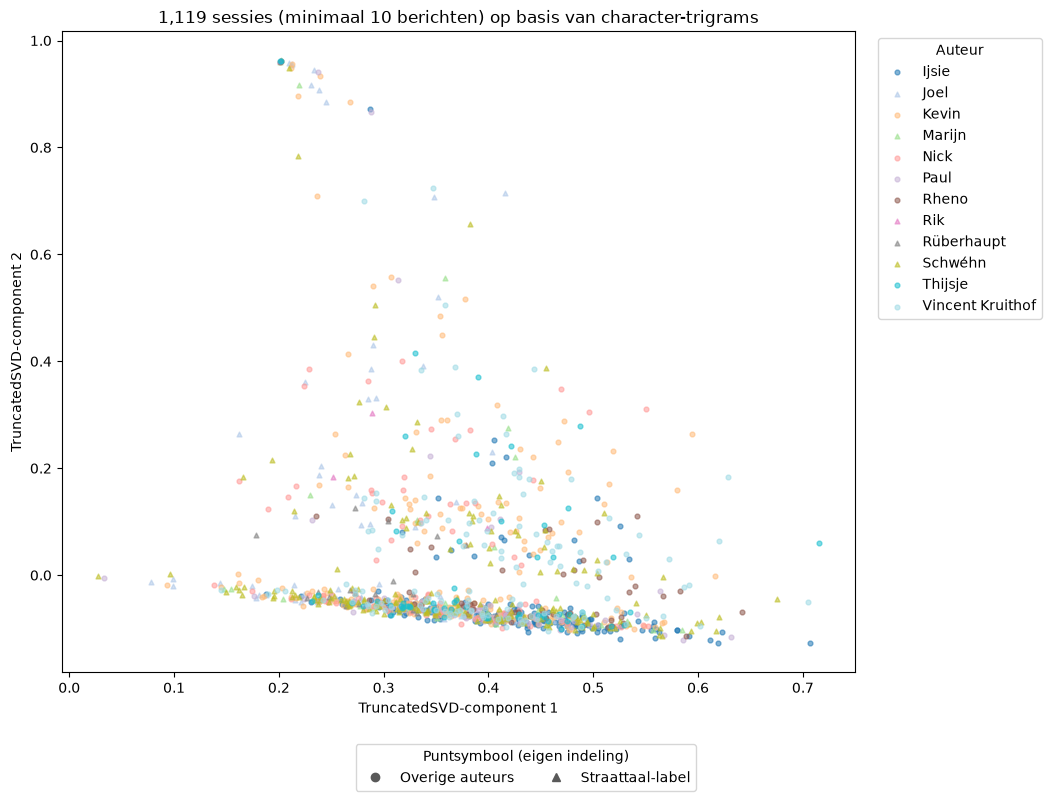

Gebruikte sessies: 1,119 van 21,896 (5.1%); alle sessies hebben minimaal tien berichten.
Trigrams: 7,350; variantie in de twee componenten samen: 5.3%.


In [181]:
STREET_SLANG_AUTHORS = {"Rüberhaupt", "Schwéhn", "Joel", "Marijn", "Rik"}
session_units = (
    chat_units.loc[chat_units.n_messages >= 10]
    .sort_values(["author", "session_id"])
    .reset_index(drop=True)
    .copy()
)
session_units["street_slang"] = session_units.author.isin(STREET_SLANG_AUTHORS)

session_trigrams = TfidfVectorizer(
    analyzer="char", ngram_range=(3, 3), min_df=2
)
session_trigram_matrix = session_trigrams.fit_transform(session_units.message)
session_svd = TruncatedSVD(n_components=2, random_state=42)
session_coordinates = session_svd.fit_transform(session_trigram_matrix)

authors = sorted(session_units.author.unique())
author_colors = plt.get_cmap("tab20", len(authors))
fig, ax = plt.subplots(figsize=(13, 8))
for i, author in enumerate(authors):
    mask = session_units.author.eq(author).to_numpy()
    ax.scatter(
        session_coordinates[mask, 0],
        session_coordinates[mask, 1],
        color=author_colors(i),
        marker="^" if author in STREET_SLANG_AUTHORS else "o",
        label=author,
        s=12,
        alpha=0.55,
    )

ax.set_title(f"{len(session_units):,} sessies (minimaal 10 berichten) op basis van character-trigrams")
ax.set_xlabel("TruncatedSVD-component 1")
ax.set_ylabel("TruncatedSVD-component 2")
ax.legend(title="Auteur", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.legend(
    handles=[
        Line2D([], [], color="0.35", marker="o", linestyle="None", label="Overige auteurs"),
        Line2D([], [], color="0.35", marker="^", linestyle="None", label="Straattaal-label"),
    ],
    title="Puntsymbool (eigen indeling)",
    loc="lower center",
    ncol=2,
)
fig.tight_layout(rect=(0, 0.08, 0.82, 1))
plt.show()

print(
    f"Gebruikte sessies: {len(session_units):,} van {len(chat_units):,} "
    f"({len(session_units) / len(chat_units):.1%}); alle sessies hebben minimaal tien berichten."
)
print(
    f"Trigrams: {session_trigram_matrix.shape[1]:,}; "
    f"variantie in de twee componenten samen: "
    f"{session_svd.explained_variance_ratio_.sum():.1%}."
)

### Dezelfde sessies met PCA

Ter vergelijking voeren we PCA uit op dezelfde TF-IDF-trigrammatrix. PCA centreert de kolommen, dus de sparse matrix wordt tijdelijk dicht gemaakt; met `float32` blijft dat werkgeheugen beperkt. De assen en verklaarde variantie zijn daarom niet één-op-één vergelijkbaar met TruncatedSVD, die niet centreert.

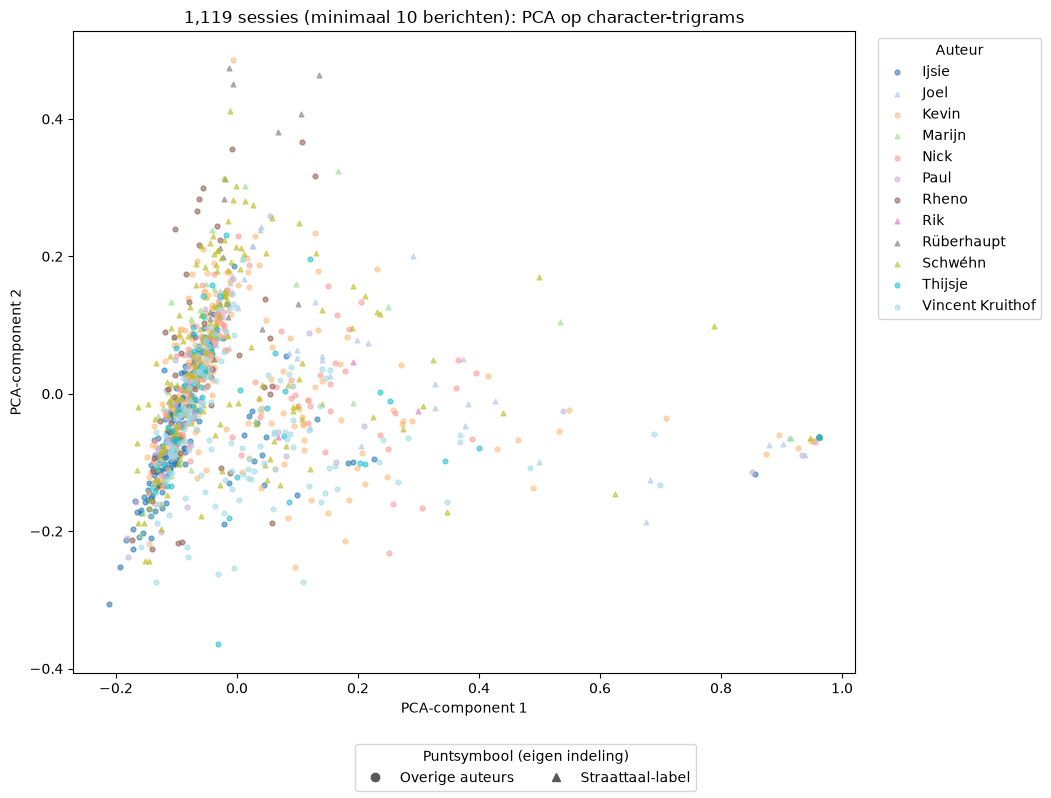

PCA-variantie: component 1 4.2%; component 2 1.5%; samen 5.7%.


In [182]:
session_pca_matrix = session_trigram_matrix.astype(np.float32).toarray()
session_pca = PCA(n_components=2, svd_solver="randomized", random_state=42)
session_pca_coordinates = session_pca.fit_transform(session_pca_matrix)

fig, ax = plt.subplots(figsize=(13, 8))
for i, author in enumerate(authors):
    mask = session_units.author.eq(author).to_numpy()
    ax.scatter(
        session_pca_coordinates[mask, 0],
        session_pca_coordinates[mask, 1],
        color=author_colors(i),
        marker="^" if author in STREET_SLANG_AUTHORS else "o",
        label=author,
        s=12,
        alpha=0.55,
    )

ax.set_title(f"{len(session_units):,} sessies (minimaal 10 berichten): PCA op character-trigrams")
ax.set_xlabel("PCA-component 1")
ax.set_ylabel("PCA-component 2")
ax.legend(title="Auteur", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.legend(
    handles=[
        Line2D([], [], color="0.35", marker="o", linestyle="None", label="Overige auteurs"),
        Line2D([], [], color="0.35", marker="^", linestyle="None", label="Straattaal-label"),
    ],
    title="Puntsymbool (eigen indeling)",
    loc="lower center",
    ncol=2,
)
fig.tight_layout(rect=(0, 0.08, 0.82, 1))
plt.show()

pca_variance = session_pca.explained_variance_ratio_
print(
    f"PCA-variantie: component 1 {pca_variance[0]:.1%}; "
    f"component 2 {pca_variance[1]:.1%}; "
    f"samen {pca_variance.sum():.1%}."
)

## Dezelfde sessieanalyse voor Squad plus chicks

Hier herhalen we de trigramanalyse apart voor Squad plus chicks: sessies van minimaal tien berichten, TF-IDF-charactertrigrams, gevolgd door TruncatedSVD en PCA. Sessies worden binnen deze chat en per auteur gevormd met dezelfde grens van 60 minuten.

In [183]:
from io import TextIOWrapper
from zipfile import ZipFile

CHICKS_ZIP_PATH = ROOT / "data" / "raw" / "Squad plus chicks 🐥.zip"
if not CHICKS_ZIP_PATH.is_file():
    raise FileNotFoundError(f"Chatarchief niet gevonden: {CHICKS_ZIP_PATH}")

with ZipFile(CHICKS_ZIP_PATH) as archive:
    text_members = [
        name for name in archive.namelist() if name.lower().endswith(".txt")
    ]
    if len(text_members) != 1:
        raise ValueError(
            f"Verwacht precies één .txt-chatbestand in {CHICKS_ZIP_PATH.name}; "
            f"gevonden: {len(text_members)}."
        )

    chicks_records = []
    last_record_kind = None
    with TextIOWrapper(
        archive.open(text_members[0]), encoding="utf-8-sig"
    ) as chat_file:
        for line_number, line in enumerate(chat_file, start=1):
            line = line.rstrip("\r\n")
            message_match = MESSAGE_HEADER.match(line)
            if message_match:
                timestamp_text, author, message = message_match.groups()
                timestamp = pd.to_datetime(
                    timestamp_text,
                    format=CHAT_DATETIME_FORMAT,
                    utc=True,
                    errors="raise",
                )
                chicks_records.append(
                    [timestamp, author.strip(), message.strip()]
                )
                last_record_kind = "message"
                continue

            if TIMESTAMPED_LINE.match(line):
                last_record_kind = "event"
                continue

            if last_record_kind == "message":
                chicks_records[-1][2] = (
                    f"{chicks_records[-1][2]}\n{line}".strip()
                )
            elif last_record_kind != "event" and line.strip():
                raise ValueError(
                    f"Onverwachte regel zonder tijdstempel of voorafgaand record "
                    f"op regel {line_number}."
                )

chicks_messages = pd.DataFrame(
    chicks_records, columns=["timestamp", "author", "message"]
)
chicks_messages["author"] = chicks_messages["author"].replace(
    {"Eikel": "Joel", "Vincent": "Vincent Kruithof"}
)
unnamed_chicks_author = chicks_messages["author"].str.fullmatch(
    r"\+?[\d\s().-]+"
) | chicks_messages["author"].str.casefold().isin({"", "null", "unknown"})
chicks_messages = chicks_messages.loc[~unnamed_chicks_author].copy()
print(
    f"Squad plus chicks: {len(chicks_messages):,} berichten, "
    f"{chicks_messages.author.nunique():,} auteurs."
)

Squad plus chicks: 11,709 berichten, 14 auteurs.


In [184]:
chicks_chat = chicks_messages.sort_values(
    ["author", "timestamp"]
).reset_index(drop=True)
chicks_chat["session_id"] = sessionize(
    chicks_chat, "timestamp", "author", 60 * 60
)
chicks_chat_units = merge_messages(chicks_chat, ["author", "session_id"])
chicks_session_units = (
    chicks_chat_units.loc[chicks_chat_units.n_messages >= 10]
    .sort_values(["author", "session_id"])
    .reset_index(drop=True)
    .copy()
)
chicks_session_units["street_slang"] = chicks_session_units.author.isin(
    STREET_SLANG_AUTHORS
)
print(
    f"Sessies met minimaal tien berichten: {len(chicks_session_units):,} "
    f"van {len(chicks_chat_units):,} "
    f"({len(chicks_session_units) / len(chicks_chat_units):.1%})."
)

Sessies met minimaal tien berichten: 128 van 5,212 (2.5%).


### TruncatedSVD voor Squad plus chicks

De matrix gebruikt dezelfde character-trigraminstellingen als hierboven. De punten zijn sessies; kleur staat voor auteur en het symbool voor de zelf ingedeelde straattaalgroep. Deze projectie is verkennend.

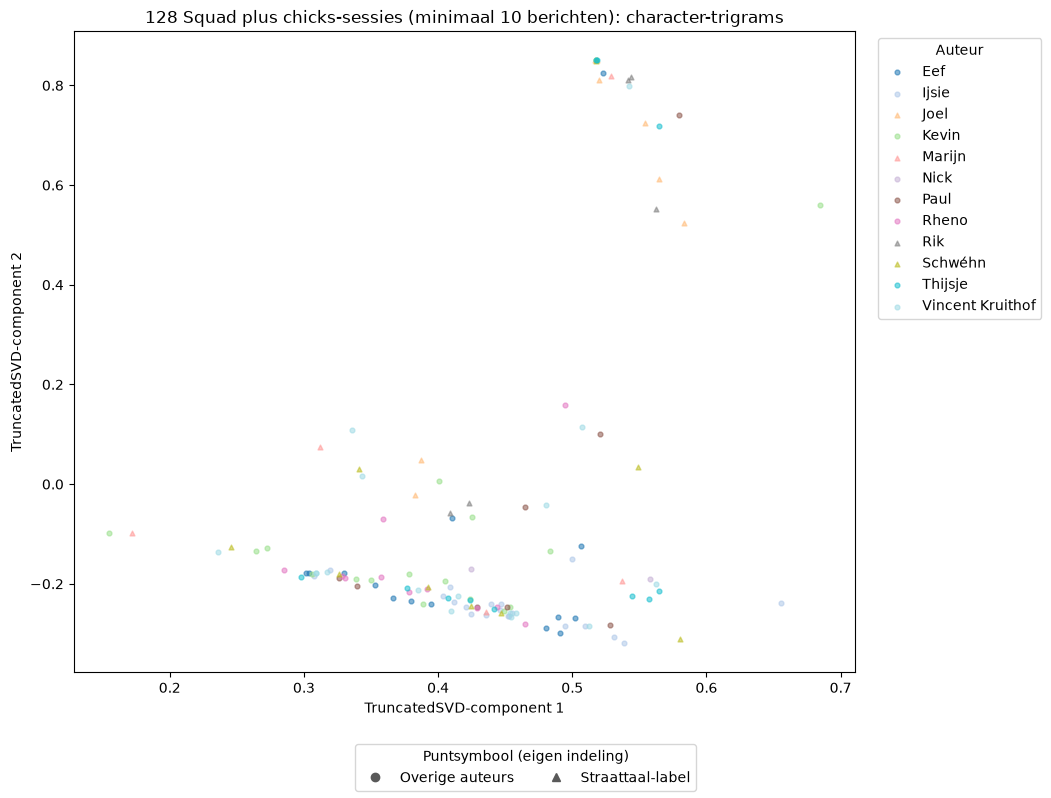

Trigrams: 2,405; variantie in de twee componenten samen: 16.9%.


In [185]:
chicks_session_trigrams = TfidfVectorizer(
    analyzer="char", ngram_range=(3, 3), min_df=2
)
chicks_trigram_matrix = chicks_session_trigrams.fit_transform(
    chicks_session_units.message
)
chicks_svd = TruncatedSVD(n_components=2, random_state=42)
chicks_svd_coordinates = chicks_svd.fit_transform(chicks_trigram_matrix)

chicks_authors = sorted(chicks_session_units.author.unique())
chicks_author_colors = plt.get_cmap("tab20", len(chicks_authors))
fig, ax = plt.subplots(figsize=(13, 8))
for i, author in enumerate(chicks_authors):
    mask = chicks_session_units.author.eq(author).to_numpy()
    ax.scatter(
        chicks_svd_coordinates[mask, 0],
        chicks_svd_coordinates[mask, 1],
        color=chicks_author_colors(i),
        marker="^" if author in STREET_SLANG_AUTHORS else "o",
        label=author,
        s=12,
        alpha=0.55,
    )

ax.set_title(
    f"{len(chicks_session_units):,} Squad plus chicks-sessies "
    "(minimaal 10 berichten): character-trigrams"
)
ax.set_xlabel("TruncatedSVD-component 1")
ax.set_ylabel("TruncatedSVD-component 2")
ax.legend(title="Auteur", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.legend(
    handles=[
        Line2D([], [], color="0.35", marker="o", linestyle="None", label="Overige auteurs"),
        Line2D([], [], color="0.35", marker="^", linestyle="None", label="Straattaal-label"),
    ],
    title="Puntsymbool (eigen indeling)",
    loc="lower center",
    ncol=2,
)
fig.tight_layout(rect=(0, 0.08, 0.82, 1))
plt.show()

print(
    f"Trigrams: {chicks_trigram_matrix.shape[1]:,}; "
    f"variantie in de twee componenten samen: "
    f"{chicks_svd.explained_variance_ratio_.sum():.1%}."
)

### PCA voor Squad plus chicks

PCA centreert de TF-IDF-kolommen en zet de sparse matrix daarom tijdelijk dicht om. `float32` beperkt het benodigde geheugen. De componenten en variantiepercentages zijn niet één-op-één vergelijkbaar met TruncatedSVD. In de grafiek zijn sessies met een PCA-component-1-score boven 0,5 rood; de overige sessies zijn grijs.

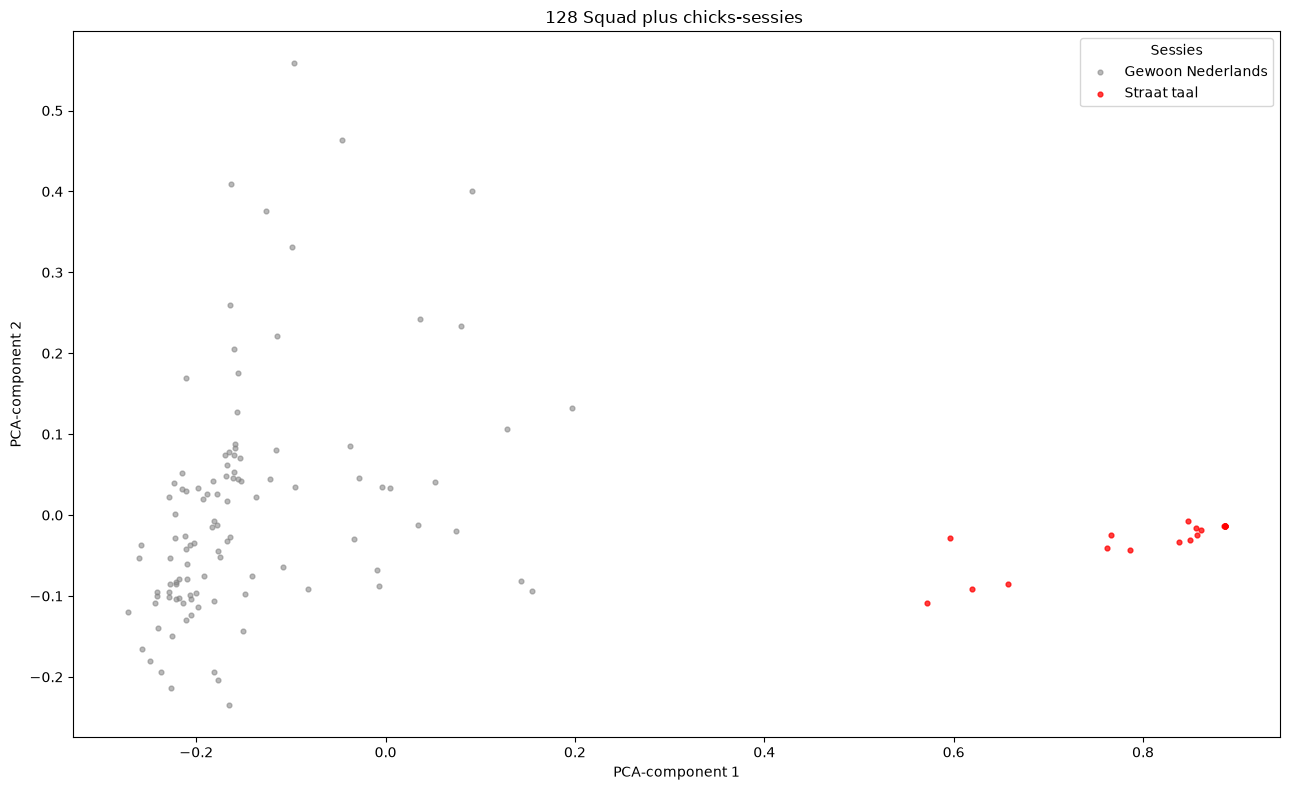

PCA-variantie: component 1 16.0%; component 2 2.2%; samen 18.2%.Alleen Sessies met minimaal 10 berichten zijn meegenomen


In [ ]:
chicks_pca_matrix = chicks_trigram_matrix.astype(np.float32).toarray()
chicks_pca = PCA(n_components=2, svd_solver="randomized", random_state=42)
chicks_pca_coordinates = chicks_pca.fit_transform(chicks_pca_matrix)

chicks_high_pc1 = chicks_pca_coordinates[:, 0] > 0.5

fig, ax = plt.subplots(figsize=(13, 8))
ax.scatter(
    chicks_pca_coordinates[~chicks_high_pc1, 0],
    chicks_pca_coordinates[~chicks_high_pc1, 1],
    color="gray",
    label="Gewoon Nederlands",
    s=12,
    alpha=0.55,
)
ax.scatter(
    chicks_pca_coordinates[chicks_high_pc1, 0],
    chicks_pca_coordinates[chicks_high_pc1, 1],
    color="red",
    label="Straat taal",
    s=12,
    alpha=0.75,
)

ax.set_title("Straattaal in de groep. Trigrams tonen een verschil tussen het taalgebruik in de vriendengroep.")
ax.set_xlabel("PCA-component 1")
ax.set_ylabel("PCA-component 2")
ax.legend(title="Sessies")
fig.tight_layout()
plt.show()

chicks_pca_variance = chicks_pca.explained_variance_ratio_
print(
    f"PCA-variantie: component 1 {chicks_pca_variance[0]:.1%}; "
    f"component 2 {chicks_pca_variance[1]:.1%}; "
    f"samen {chicks_pca_variance.sum():.1%}."
    f"Alleen Sessies met minimaal 10 berichten zijn meegenomen"
)

### Schudtest voor de PCA-projectie

We schudden de TF-IDF-waarden binnen elke trigramkolom onafhankelijk over de sessies. Zo blijft de verdeling per trigram gelijk, maar gaat de koppeling tussen trigrams binnen een sessie verloren. De sessies uit elke shuffle projecteren we op de oorspronkelijke PCA-assen. We tellen sessies in het vooraf afgesproken gebied PC1 > 0,5 en −0,1 ≤ PC2 ≤ 0,05, en vergelijken die telling met 999 shuffles. Omdat dit gebied na het bekijken van de plot is gekozen, is de p-waarde verkennend.

In [ ]:
rng = np.random.default_rng(42)
chicks_shuffled_matrix = np.column_stack(
    [rng.permutation(column) for column in chicks_pca_matrix.T]
)
chicks_shuffled_pca = PCA(
    n_components=2, svd_solver="randomized", random_state=42
)
chicks_shuffled_coordinates = chicks_shuffled_pca.fit_transform(
    chicks_shuffled_matrix
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(
    chicks_pca_coordinates[~chicks_high_pc1, 0],
    chicks_pca_coordinates[~chicks_high_pc1, 1],
    color="gray",
    s=12,
    alpha=0.55,
)
axes[0].scatter(
    chicks_pca_coordinates[chicks_high_pc1, 0],
    chicks_pca_coordinates[chicks_high_pc1, 1],
    color="red",
    s=12,
    alpha=0.75,
)
axes[0].set_title("Oorspronkelijke sessies")
axes[0].set_xlabel("PCA-component 1")
axes[0].set_ylabel("PCA-component 2")

axes[1].scatter(
    chicks_shuffled_coordinates[:, 0],
    chicks_shuffled_coordinates[:, 1],
    color="gray",
    s=12,
    alpha=0.55,
)
axes[1].set_title("Trigramwaarden per kolom geschud")
axes[1].set_xlabel("PCA-component 1")
axes[1].set_ylabel("PCA-component 2")
fig.tight_layout()
plt.show()

print(
    f"Verklaarde variantie in 2 componenten: oorspronkelijk "
    f"{chicks_pca.explained_variance_ratio_.sum():.1%}; "
    f"geschud {chicks_shuffled_pca.explained_variance_ratio_.sum():.1%}."
)

PC1_THRESHOLD = 0.5
PC2_LOWER, PC2_UPPER = -0.1, 0.05
SHUFFLE_REPETITIONS = 999

def count_sessions_in_region(coordinates):
    return int(
        (
            (coordinates[:, 0] > PC1_THRESHOLD)
            & (coordinates[:, 1] >= PC2_LOWER)
            & (coordinates[:, 1] <= PC2_UPPER)
        ).sum()
    )

chicks_observed_region_count = count_sessions_in_region(
    chicks_pca_coordinates
)
chicks_null_region_counts = np.empty(SHUFFLE_REPETITIONS, dtype=int)
rng = np.random.default_rng(42)
for repetition in range(SHUFFLE_REPETITIONS):
    row_permutations = np.argsort(
        rng.random(chicks_pca_matrix.shape), axis=0
    )
    shuffled_matrix = np.take_along_axis(
        chicks_pca_matrix, row_permutations, axis=0
    )
    shuffled_coordinates = chicks_pca.transform(shuffled_matrix)
    chicks_null_region_counts[repetition] = count_sessions_in_region(
        shuffled_coordinates
    )

chicks_shuffle_p_value = (
    1 + np.count_nonzero(
        chicks_null_region_counts >= chicks_observed_region_count
    )
) / (SHUFFLE_REPETITIONS + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    chicks_null_region_counts,
    bins=np.arange(chicks_null_region_counts.max() + 2) - 0.5,
    color="gray",
    edgecolor="white",
)
ax.axvline(
    chicks_observed_region_count,
    color="red",
    linewidth=2,
    label=f"Geobserveerd: {chicks_observed_region_count}",
)
ax.set_title("Sessies in het PC1/PC2-gebied: shuffle-nulmodel")
ax.set_xlabel("Aantal sessies in PC1 > 0,5 en −0,1 ≤ PC2 ≤ 0,05")
ax.set_ylabel("Aantal shuffles")
ax.legend()
fig.tight_layout()
plt.show()

print(
    f"Geobserveerd: {chicks_observed_region_count}/{len(chicks_pca_matrix)} sessies. "
    f"Shuffle-nulmodel (n={SHUFFLE_REPETITIONS}): gemiddelde "
    f"{chicks_null_region_counts.mean():.2f}, "
    f"95e percentiel {np.quantile(chicks_null_region_counts, 0.95):.0f}; "
    f"eenzijdige p-waarde {chicks_shuffle_p_value:.4f}."
)

### Trigrams bij hoge PCA-component-1-scores

Deze tabel vergelijkt voor elke component de bovenste 10% sessies met de overige sessies. De bijdrage is `(TF-IDF-waarde - gemiddelde) × componentlading`; een positieve verschilscore betekent dat het trigram de hoge score op die component relatief omhoog duwt. De kolom 'component' geeft aan of het trigram vooral bij hoge PC1, hoge PC2 of beide hoort. Dit beschrijft de PCA-projectie en is geen oorzakelijk effect.

In [187]:
chicks_feature_names = chicks_session_trigrams.get_feature_names_out()
chicks_contribution_differences = {}
chicks_high_score_counts = {}
for component in range(2):
    scores = chicks_pca_coordinates[:, component]
    cutoff = np.quantile(scores, 0.9)
    high_score = scores >= cutoff
    contributions = (
        chicks_pca_matrix - chicks_pca.mean_
    ) * chicks_pca.components_[component]
    high_mean = contributions[high_score].mean(axis=0)
    other_mean = contributions[~high_score].mean(axis=0)
    chicks_contribution_differences[component + 1] = high_mean - other_mean
    chicks_high_score_counts[component + 1] = (int(high_score.sum()), float(cutoff))

chicks_pc1_differences = chicks_contribution_differences[1]
chicks_pc2_differences = chicks_contribution_differences[2]
chicks_pc1_top = set(np.argsort(chicks_pc1_differences)[-15:])
chicks_pc2_top = set(np.argsort(chicks_pc2_differences)[-15:])
chicks_selected_features = sorted(chicks_pc1_top | chicks_pc2_top)

def contributing_components(feature_index):
    pc1_positive = feature_index in chicks_pc1_top and chicks_pc1_differences[feature_index] > 0
    pc2_positive = feature_index in chicks_pc2_top and chicks_pc2_differences[feature_index] > 0
    if pc1_positive and pc2_positive:
        return "PC1 en PC2"
    if pc1_positive:
        return "PC1"
    if pc2_positive:
        return "PC2"
    return ""

chicks_pc_contribution_table = pd.DataFrame(
    {
        "trigram": chicks_feature_names[chicks_selected_features],
        "component": [contributing_components(i) for i in chicks_selected_features],
        "verschil hoge PC1": chicks_pc1_differences[chicks_selected_features],
        "verschil hoge PC2": chicks_pc2_differences[chicks_selected_features],
    }
).sort_values("component", ascending=False).reset_index(drop=True)

print(
    f"Top 10% hoge scores: PC1 {chicks_high_score_counts[1][0]} sessies "
    f"(score ≥ {chicks_high_score_counts[1][1]:.3f}); PC2 "
    f"{chicks_high_score_counts[2][0]} sessies "
    f"(score ≥ {chicks_high_score_counts[2][1]:.3f}). "
    "De verschillen zijn gemiddelde trigrambijdragen in hoge-score-sessies "
    "ten opzichte van de overige sessies."
)
display(
    chicks_pc_contribution_table.style.format(
        {
            "verschil hoge PC1": "{:.4f}",
            "verschil hoge PC2": "{:.4f}",
        }
    )
)

Top 10% hoge scores: PC1 13 sessies (score ≥ 0.801); PC2 13 sessies (score ≥ 0.144). De verschillen zijn gemiddelde trigrambijdragen in hoge-score-sessies ten opzichte van de overige sessies.


,trigram,component,verschil hoge PC1,verschil hoge PC2
0,we,PC2,0.0079,0.0026
1,😂😂,PC2,0.0001,0.0023
2,aha,PC2,0.0004,0.0370
3,ahh,PC2,0.0000,0.0016
4,at,PC2,0.0021,0.0024
5,en,PC2,0.0200,0.0130
6,ha,PC2,0.0000,0.0016
7,hah,PC2,0.0005,0.0607
8,hhh,PC2,0.0001,0.0028
9,lli,PC2,0.0004,0.0017


In [ ]:
chicks_chat_checkable = chicks_chat_units.loc[
    chicks_chat_units.n_messages >= 5
].reset_index(drop=True)
chicks_enough = chicks_chat_checkable.author.value_counts()
chicks_racers = chicks_chat_checkable.loc[
    chicks_chat_checkable.author.isin(
        chicks_enough[chicks_enough >= 20].index
    )
]

if chicks_racers.author.nunique() >= 2:
    chicks_scores, chicks_style, chicks_trigrams = race(
        chicks_racers, per_author=PER_AUTHOR
    )
    print("Squad plus chicks — sessies met minstens vijf berichten:")
    for name, accuracy in chicks_scores.items():
        print(f"{name:>35s}: {accuracy:.1%}")
    print()
    for author, strongest in strongest_trigrams(
        chicks_style, chicks_trigrams
    ).items():
        print(f"{author:16s} {'  '.join(repr(t) for t in strongest)}")
else:
    print(
        "Minder dan twee Squad plus chicks-auteurs hebben twintig sessies "
        "van minstens vijf berichten; de schrijfstijlrace kan niet worden uitgevoerd."
    )

chicks_emoji_pattern = re.compile(
    r"[\U0001F000-\U0001FAFF\u2300-\u23FF\u2600-\u27BF\u20E3]"
)
chicks_emoji_messages = chicks_messages.loc[
    chicks_messages.message.map(
        lambda message: bool(chicks_emoji_pattern.search(message))
    )
].copy()
chicks_emoji_author_counts = chicks_emoji_messages.author.value_counts()
chicks_emoji_racers = chicks_emoji_messages.loc[
    chicks_emoji_messages.author.isin(
        chicks_emoji_author_counts[chicks_emoji_author_counts >= 20].index
    )
]

if chicks_emoji_racers.author.nunique() >= 2:
    chicks_balanced_emoji_messages = (
        chicks_emoji_racers.sample(frac=1, random_state=42)
        .groupby("author")
        .head(PER_AUTHOR)
    )
    chicks_emoji_train, chicks_emoji_test = train_test_split(
        chicks_balanced_emoji_messages,
        test_size=0.3,
        stratify=chicks_balanced_emoji_messages.author,
        random_state=42,
    )
    chicks_emoji_trigrams = CountVectorizer(
        analyzer="char", ngram_range=(3, 3), min_df=2
    )
    chicks_emoji_trigram_model = LogisticRegression(max_iter=1000).fit(
        chicks_emoji_trigrams.fit_transform(chicks_emoji_train.message),
        chicks_emoji_train.author,
    )
    chicks_emoji_accuracy = chicks_emoji_trigram_model.score(
        chicks_emoji_trigrams.transform(chicks_emoji_test.message),
        chicks_emoji_test.author,
    )
    chicks_emoji_predictions = chicks_emoji_trigram_model.predict(
        chicks_emoji_trigrams.transform(chicks_emoji_test.message)
    )
    chicks_emoji_per_author_accuracy = (
        pd.DataFrame(
            {
                "author": chicks_emoji_test.author.to_numpy(),
                "correct": chicks_emoji_predictions
                == chicks_emoji_test.author.to_numpy(),
            }
        )
        .groupby("author")["correct"]
        .mean()
    )
    chicks_emoji_baseline = chicks_emoji_test.author.value_counts(
        normalize=True
    ).max()
    print(
        f"\nSquad plus chicks emoji-berichten: "
        f"{len(chicks_emoji_racers):,} berichten van "
        f"{chicks_emoji_racers.author.nunique()} auteurs; "
        f"trigram-accuracy {chicks_emoji_accuracy:.1%} "
        f"(meerderheidsbaseline {chicks_emoji_baseline:.1%})."
    )
    chicks_emoji_trigrams_by_author = strongest_trigrams(
        chicks_emoji_trigram_model, chicks_emoji_trigrams, n=12
    )
    chicks_emoji_author_summary = pd.DataFrame(
        {
            "trigrams": {
                author: "  ".join(repr(trigram) for trigram in trigrams)
                for author, trigrams in chicks_emoji_trigrams_by_author.items()
            },
            "accuracy": chicks_emoji_per_author_accuracy,
        }
    ).rename_axis("auteur")
    display(
        chicks_emoji_author_summary.style.format({"accuracy": "{:.1%}"})
    )
else:
    print(
        "Onvoldoende Squad plus chicks-auteurs met minstens twintig "
        "emoji-berichten voor classificatie."
    )

In [188]:
chat_acc, chat_n = self_retrieval_accuracy(
    chat, ["author", "session_id"], min_messages=5, n_eval=N_EVAL
)
if chat_n:
    print(
        f"{chat_acc:.1%} van de eerste helften vindt de eigen tweede helft "
        f"terug (n={chat_n}, toeval {1 / chat_n:.1%})"
    )
else:
    print("Geen sessies met vijf of meer berichten; deze controle kan niet worden uitgevoerd.")

8.2% van de eerste helften vindt de eigen tweede helft terug (n=400, toeval 0.2%)


In [189]:
enough = chat_checkable.author.value_counts()
racers = chat_checkable[
    chat_checkable.author.isin(enough[enough >= 20].index)
]
if racers.author.nunique() >= 2:
    chat_scores, chat_style, chat_trigrams = race(
        racers, per_author=PER_AUTHOR
    )
    for name, accuracy in chat_scores.items():
        print(f"{name:>35s}: {accuracy:.1%}")
    print()
    for author, strongest in strongest_trigrams(
        chat_style, chat_trigrams
    ).items():
        print(f"{author:12s} {'  '.join(repr(t) for t in strongest)}")
else:
    print(
        "Minder dan twee auteurs hebben twintig sessies van vijf of meer berichten; "
        "de schrijfstijlrace kan niet worden uitgevoerd."
    )

emoji_pattern = re.compile(r"[\U0001F000-\U0001FAFF\u2300-\u23FF\u2600-\u27BF\u20E3]")
emoji_messages = messages.loc[
    messages["message"].map(
        lambda message: bool(emoji_pattern.search(message))
    )
].copy()
emoji_author_counts = emoji_messages.author.value_counts()
emoji_racers = emoji_messages.loc[
    emoji_messages.author.isin(emoji_author_counts[emoji_author_counts >= 20].index)
]

if emoji_racers.author.nunique() >= 2:
    balanced_emoji_messages = (
        emoji_racers.sample(frac=1, random_state=42)
        .groupby("author")
        .head(PER_AUTHOR)
    )
    emoji_train, emoji_test = train_test_split(
        balanced_emoji_messages,
        test_size=0.3,
        stratify=balanced_emoji_messages.author,
        random_state=42,
    )
    emoji_trigrams = CountVectorizer(
        analyzer="char", ngram_range=(3, 3), min_df=2
    )
    emoji_trigram_model = LogisticRegression(max_iter=1000).fit(
        emoji_trigrams.fit_transform(emoji_train.message), emoji_train.author
    )
    emoji_accuracy = emoji_trigram_model.score(
        emoji_trigrams.transform(emoji_test.message), emoji_test.author
    )
    emoji_predictions = emoji_trigram_model.predict(
        emoji_trigrams.transform(emoji_test.message)
    )
    emoji_per_author_accuracy = (
        pd.DataFrame(
            {
                "author": emoji_test.author.to_numpy(),
                "correct": emoji_predictions == emoji_test.author.to_numpy(),
            }
        )
        .groupby("author")["correct"]
        .mean()
    )
    emoji_baseline = emoji_test.author.value_counts(normalize=True).max()
    print(
        f"Emoji-berichten: {len(emoji_racers):,} berichten van "
        f"{emoji_racers.author.nunique()} auteurs; "
        f"trigram-accuracy {emoji_accuracy:.1%} "
        f"(meerderheidsbaseline {emoji_baseline:.1%})."
    )
    emoji_trigrams_by_author = strongest_trigrams(
        emoji_trigram_model, emoji_trigrams, n=12
    )
    emoji_author_summary = pd.DataFrame(
        {
            "trigrams": {
                author: "  ".join(repr(trigram) for trigram in trigrams)
                for author, trigrams in emoji_trigrams_by_author.items()
            },
            "accuracy": emoji_per_author_accuracy,
        }
    ).rename_axis("auteur")
    display(
        emoji_author_summary.style.format({"accuracy": "{:.1%}"})
    )
else:
    print("Onvoldoende auteurs met minstens twintig emoji-berichten voor classificatie.")

   raad de meest voorkomende auteur: 16.4%
                 trigramfrequenties: 54.4%
                 sentence embedding: 35.9%

Ijsie        'eeh'  ' k '  '😂😂 '  ' t '  ' ai'  ' 😂😂'  'eh '  ' f '
Joel         ' 🐦 '  'n <'  'on '  'een'  ' 😳 '  ' i '  'uuh'  ' do'
Kevin        ' 😏 '  'jaa'  ' 😂 '  'ooh'  'aa '  'uuh'  '😂😂 '  'uhm'
Marijn       '> <'  '😘 <'  'ha '  ' <m'  'aha'  'a v'  'heh'  'yo '
Nick         ' 😂 '  ' oh'  '.. '  ' t '  'aa '  'jaa'  ' 1 '  ' fi'
Paul         'ha '  'oka'  'e t'  'kay'  'ad '  'tho'  '> <'  'ay '
Rheno        'hah'  'eee'  'aaa'  'n, '  'cee'  'ah '  'gwn'  ' gw'
Rik          '❤❤❤'  'ame'  'sss'  'hop'  'as '  'bal'  's b'  'wil'
Rüberhaupt   'aha'  'hah'  'ers'  ' vi'  ' 💪🏿'  'ter'  'tre'  'ess'
Schwéhn      'ws '  ' xd'  'hhh'  ' ? '  ' em'  ' fr'  ' gw'  'gwn'
Thijsje      'hw '  '!! '  'ff '  'ja '  'oke'  'ohw'  'fon'  'afo'
Vincent Kruithof 'mn '  ' mn'  'hem'  'n> '  's, '  ' 🙈 '  'm j'  'ick'
Emoji-berichten: 9,704 berichten van 13 auteurs; t

,trigrams,accuracy
auteur,,
Ijsie,' k ' 'an😂' 'eeh' '😂😂 ' ' be' 'e😂😂' 'jat' 'oh ' 'ato' ' m ' 't a' 'en😉',28.3%
Joel,'✊🏻💦' '🐑👈🏿' 'eva' '😳😳😳' 'we ' 'ys😘' 'of ' 'zws' 'wie' 'en😳' 'ere' 'hey',61.1%
Kevin,'n 😂' 's 😂' 'me ' 't 😂' 'n 😏' 's 😊' ' ❤❤' ' ☝🏼' 'je ' 'e 😂' 'sti' 'us ',15.6%
Marijn,'🤷🏻\u200d' '🏻\u200d♂' '😂😂 ' 'e 😘' ' th' '😔😔😔' 'l n' 'ch ' 't! ' 'heu' 'nge' 'at!',6.4%
Nick,'en😜' ' t ' '❤️😘' 'en❤' 'oh😂' 'dag' 'aa😂' 'k o' '😭😭😭' '💥💥💥' '💁🏼\u200d' 'en😂',12.2%
Paul,'et😭' 'eej' '🤷🏼\u200d' 'hoi' 'af😂' 'heb' 'd m' 'raa' 'ake' 't f' 'nee' 'i g',10.2%
Rheno,'sss' 'mr ' 'it😂' '🏼\u200d♂' ' 🫶🏻' 'eee' 'o😂😂' 'aaa' 'may' 'hoo' 'd 🍾' 'hah',45.6%
Rik,'🙋\u200d♂' '🍆💦💦' '🙋🏾\u200d' '🏾\u200d♂' 'ree' '🎊🎊🎊' 'n🎊🎊' ' lo' 'nig' ' jo' 'at❤' 'gei',23.6%
Rüberhaupt,'💪💪💪' '👍👍👍' '🏿💪🏿' '😎😎😎' '🏿👆🏿' '👆🏿👆' '😊😊😊' '💪🏿💪' '😱😱😱' '🙏🙏🙏' 'in💪' '💁🏿\u200d',41.1%
